#Food Delivery Analytics, Recommendation & Forecasting

# Project Overview

## Problem Statement

A food delivery company wants to analyze customer ordering behavior, identify popular food
combinations, recommend relevant food items, and forecast future order demand.

Using the provided
dataset, perform data analysis, market basket analysis, recommendation generation, and sales.

##Task 1 – Data Loading & Exploration

● Load dataset using Pandas

● Perform:

* ○ head(), tail()

* ○ shape, columns

* ○ info(), dtypes

* ○ describe()

* ○ value_counts()

In [60]:
# Load dataset using Pandas

import pandas as pd
import numpy as np
from IPython.display import display

data = pd.read_excel('food_delivery_analytics_3000.xlsx')
data

,OrderID,CustomerID,Restaurant,FoodItem,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating,City,PaymentMethod,OrderDate
0,1,1229,Biryani House,Pizza,1,465.61,465.61,57,1,Delhi,UPI,2024-05-05
1,2,1224,Healthy Bowl,Wrap,4,96.53,386.12,42,5,Chennai,Cash,2024-02-17
2,3,1604,Taco Town,Salad,5,298.15,1490.75,10,2,Mumbai,Card,2024-08-17
3,4,1105,Pizza Point,Taco,2,191.96,383.92,34,1,Hyderabad,Card,2024-06-21
4,5,1550,Pizza Point,Wrap,3,499.71,1499.13,34,1,Delhi,Card,2024-08-23
...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2996,1024,Sushi Spot,Sandwich,5,561.70,2808.50,24,3,Mumbai,Cash,2024-04-24
2996,2997,1792,Pizza Point,Burger,2,321.62,643.24,52,2,Chennai,UPI,2024-10-26
2997,2998,1738,Sushi Spot,Wrap,4,210.30,841.20,48,5,Chennai,Card,2024-05-02
2998,2999,1505,Pasta Place,Pasta,5,248.04,1240.20,47,5,Hyderabad,Cash,2024-06-25


In [61]:
# ○ head(), tail()

print("First five rows:\n")
display(data.head())

print("Last five rows:\n")
display(data.tail())

First five rows:



,OrderID,CustomerID,Restaurant,FoodItem,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating,City,PaymentMethod,OrderDate
0,1,1229,Biryani House,Pizza,1,465.61,465.61,57,1,Delhi,UPI,2024-05-05
1,2,1224,Healthy Bowl,Wrap,4,96.53,386.12,42,5,Chennai,Cash,2024-02-17
2,3,1604,Taco Town,Salad,5,298.15,1490.75,10,2,Mumbai,Card,2024-08-17
3,4,1105,Pizza Point,Taco,2,191.96,383.92,34,1,Hyderabad,Card,2024-06-21
4,5,1550,Pizza Point,Wrap,3,499.71,1499.13,34,1,Delhi,Card,2024-08-23


Last five rows:



,OrderID,CustomerID,Restaurant,FoodItem,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating,City,PaymentMethod,OrderDate
2995,2996,1024,Sushi Spot,Sandwich,5,561.70,2808.50,24,3,Mumbai,Cash,2024-04-24
2996,2997,1792,Pizza Point,Burger,2,321.62,643.24,52,2,Chennai,UPI,2024-10-26
2997,2998,1738,Sushi Spot,Wrap,4,210.30,841.20,48,5,Chennai,Card,2024-05-02
2998,2999,1505,Pasta Place,Pasta,5,248.04,1240.20,47,5,Hyderabad,Cash,2024-06-25
2999,3000,1590,Burger Hub,Burger,5,474.97,2374.85,36,5,Mumbai,Cash,2024-04-05


In [62]:
# ○ shape, columns

print("Shape:\n",data.shape)
print("Columns:\n",data.columns)


Shape:
 (3000, 12)
Columns:
 Index(['OrderID', 'CustomerID', 'Restaurant', 'FoodItem', 'Quantity',
       'OrderValue', 'TotalAmount', 'DeliveryTime_Minutes', 'CustomerRating',
       'City', 'PaymentMethod', 'OrderDate'],
      dtype='object')


In [63]:
# ○ info(), dtypes

print("Info about dataset:\n")
display(data.info())
print("dtypes:\n")
display(data.dtypes)

Info about dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   OrderID               3000 non-null   int64  
 1   CustomerID            3000 non-null   int64  
 2   Restaurant            3000 non-null   object 
 3   FoodItem              3000 non-null   object 
 4   Quantity              3000 non-null   int64  
 5   OrderValue            3000 non-null   float64
 6   TotalAmount           3000 non-null   float64
 7   DeliveryTime_Minutes  3000 non-null   int64  
 8   CustomerRating        3000 non-null   int64  
 9   City                  3000 non-null   object 
 10  PaymentMethod         3000 non-null   object 
 11  OrderDate             3000 non-null   object 
dtypes: float64(2), int64(5), object(5)
memory usage: 281.4+ KB


None

dtypes:



,0
OrderID,int64
CustomerID,int64
Restaurant,object
FoodItem,object
Quantity,int64
OrderValue,float64
TotalAmount,float64
DeliveryTime_Minutes,int64
CustomerRating,int64
City,object


In [64]:
# ○ describe()

print("statistical summaries:\n")
data.describe()

statistical summaries:



,OrderID,CustomerID,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,1397.573000,2.994333,338.074453,1009.472437,34.916333,3.002333
std,866.169729,233.609663,1.421141,149.676468,680.124564,14.943285,1.405342
min,1.000000,1001.000000,1.000000,80.050000,80.050000,10.000000,1.000000
25%,750.750000,1187.000000,2.000000,209.707500,458.070000,22.000000,2.000000
50%,1500.500000,1392.500000,3.000000,335.030000,853.350000,35.000000,3.000000
75%,2250.250000,1604.000000,4.000000,467.722500,1465.052500,48.000000,4.000000
max,3000.000000,1800.000000,5.000000,599.990000,2997.850000,60.000000,5.000000


In [65]:
print("Value counts:\n",data.value_counts())

Value counts:
 OrderID  CustomerID  Restaurant     FoodItem  Quantity  OrderValue  TotalAmount  DeliveryTime_Minutes  CustomerRating  City       PaymentMethod  OrderDate 
1        1229        Biryani House  Pizza     1         465.61      465.61       57                    1               Delhi      UPI            2024-05-05    1
2        1224        Healthy Bowl   Wrap      4         96.53       386.12       42                    5               Chennai    Cash           2024-02-17    1
3        1604        Taco Town      Salad     5         298.15      1490.75      10                    2               Mumbai     Card           2024-08-17    1
4        1105        Pizza Point    Taco      2         191.96      383.92       34                    1               Hyderabad  Card           2024-06-21    1
5        1550        Pizza Point    Wrap      3         499.71      1499.13      34                    1               Delhi      Card           2024-08-23    1
                        

● Analyze:

* ○ Total orders

* ○ Unique customers

* ○ Unique restaurants

* ○ Orders by city

In [66]:
(data['OrderID'].unique())

array([   1,    2,    3, ..., 2998, 2999, 3000], shape=(3000,))

In [67]:
# ○ Unique customers

data['CustomerID'].nunique()

784

In [68]:
# ○ Unique restaurants

data['Restaurant'].unique()

array(['Biryani House', 'Healthy Bowl', 'Taco Town', 'Pizza Point',
       'Burger Hub', 'Pasta Place', 'Cafe Delight', 'Veg Express',
       'Grill Master', 'Sushi Spot'], dtype=object)

In [69]:
data.head(1)

,OrderID,CustomerID,Restaurant,FoodItem,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating,City,PaymentMethod,OrderDate
0,1,1229,Biryani House,Pizza,1,465.61,465.61,57,1,Delhi,UPI,2024-05-05


In [70]:
# ○ Orders by city

data.groupby('City')['OrderID'].count()

,OrderID
City,
Bangalore,563
Chennai,595
Delhi,629
Hyderabad,594
Mumbai,619


##Task 2 – Data Cleaning & Preparation

● Handle missing values

● Remove duplicates

● Validate Quantity, OrderValue, TotalAmount

● Convert OrderDate to datetime

● Create:

* ○ Year

* ○ Month

* ○ Weekday





In [71]:
# ● Handle missing values

data.isnull().sum()

,0
OrderID,0
CustomerID,0
Restaurant,0
FoodItem,0
Quantity,0
OrderValue,0
TotalAmount,0
DeliveryTime_Minutes,0
CustomerRating,0
City,0


In [72]:
# ● Remove duplicates

data.duplicated().sum()

np.int64(0)

In [73]:
# ● Validate Quantity, OrderValue, TotalAmount

data['Quantity'].unique()

array([1, 4, 5, 2, 3])

In [74]:
data['OrderValue'].describe()

,OrderValue
count,3000.000000
mean,338.074453
std,149.676468
min,80.050000
25%,209.707500
50%,335.030000
75%,467.722500
max,599.990000


In [75]:
data['TotalAmount'].describe()

,TotalAmount
count,3000.000000
mean,1009.472437
std,680.124564
min,80.050000
25%,458.070000
50%,853.350000
75%,1465.052500
max,2997.850000


In [76]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   OrderID               3000 non-null   int64  
 1   CustomerID            3000 non-null   int64  
 2   Restaurant            3000 non-null   object 
 3   FoodItem              3000 non-null   object 
 4   Quantity              3000 non-null   int64  
 5   OrderValue            3000 non-null   float64
 6   TotalAmount           3000 non-null   float64
 7   DeliveryTime_Minutes  3000 non-null   int64  
 8   CustomerRating        3000 non-null   int64  
 9   City                  3000 non-null   object 
 10  PaymentMethod         3000 non-null   object 
 11  OrderDate             3000 non-null   object 
dtypes: float64(2), int64(5), object(5)
memory usage: 281.4+ KB


In [77]:
# ● Convert OrderDate to datetime

data['OrderDate'] = pd.to_datetime(data['OrderDate'])
print(data['OrderDate'].dtype)

# --> Create: Year

data['Year'] = data['OrderDate'].dt.year

datetime64[ns]


In [78]:
# --> Month

data['Month'] = data['OrderDate'].dt.month

In [79]:
# --> Weekday

data['Weekday'] = data['OrderDate'].dt.day_name()
data

,OrderID,CustomerID,Restaurant,FoodItem,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating,City,PaymentMethod,OrderDate,Year,Month,Weekday
0,1,1229,Biryani House,Pizza,1,465.61,465.61,57,1,Delhi,UPI,2024-05-05,2024,5,Sunday
1,2,1224,Healthy Bowl,Wrap,4,96.53,386.12,42,5,Chennai,Cash,2024-02-17,2024,2,Saturday
2,3,1604,Taco Town,Salad,5,298.15,1490.75,10,2,Mumbai,Card,2024-08-17,2024,8,Saturday
3,4,1105,Pizza Point,Taco,2,191.96,383.92,34,1,Hyderabad,Card,2024-06-21,2024,6,Friday
4,5,1550,Pizza Point,Wrap,3,499.71,1499.13,34,1,Delhi,Card,2024-08-23,2024,8,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2996,1024,Sushi Spot,Sandwich,5,561.70,2808.50,24,3,Mumbai,Cash,2024-04-24,2024,4,Wednesday
2996,2997,1792,Pizza Point,Burger,2,321.62,643.24,52,2,Chennai,UPI,2024-10-26,2024,10,Saturday
2997,2998,1738,Sushi Spot,Wrap,4,210.30,841.20,48,5,Chennai,Card,2024-05-02,2024,5,Thursday
2998,2999,1505,Pasta Place,Pasta,5,248.04,1240.20,47,5,Hyderabad,Cash,2024-06-25,2024,6,Tuesday


## Task 3 – Exploratory Data Analysis

Analyze:

● Top food items by revenue

● Top restaurants

● Top customers

● Revenue by city

● Payment method distribution

● Customer ratings

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Top food items by revenue:")
data.groupby('FoodItem')['TotalAmount'].sum().sort_values(ascending=False)

Top food items by revenue:


,TotalAmount
FoodItem,
Wrap,337200.28
Biryani,325413.15
Sandwich,314966.84
Coffee,312958.93
Pizza,308228.32
Salad,306190.67
Burger,304492.51
Sushi,289492.34
Taco,264892.06


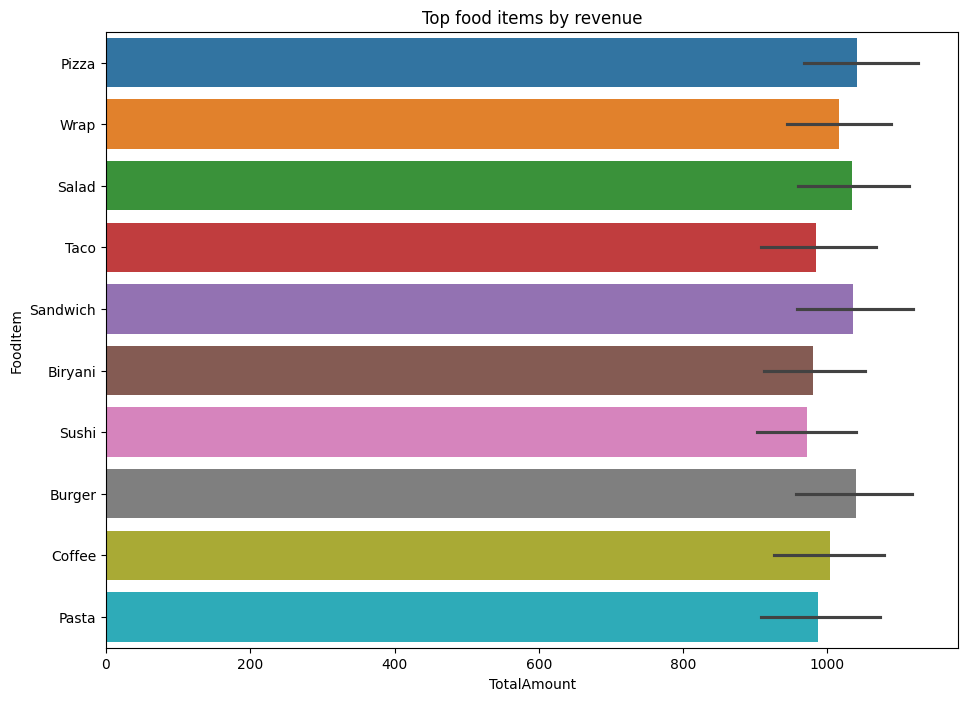

In [81]:
# Top food items by revenue (Visualize)

plt.figure(figsize=(11,8))
sns.barplot(data=data,x='TotalAmount',y='FoodItem',hue='FoodItem')
plt.title("Top food items by revenue")
plt.show()

In [82]:
print("Top restaurants:")
data.groupby('Restaurant')['TotalAmount'].sum().sort_values(ascending=False)

Top restaurants:


,TotalAmount
Restaurant,
Healthy Bowl,327202.56
Grill Master,316202.87
Veg Express,315967.22
Pizza Point,315815.32
Cafe Delight,302825.20
Sushi Spot,296465.45
Taco Town,292171.78
Biryani House,290586.02
Pasta Place,289554.91


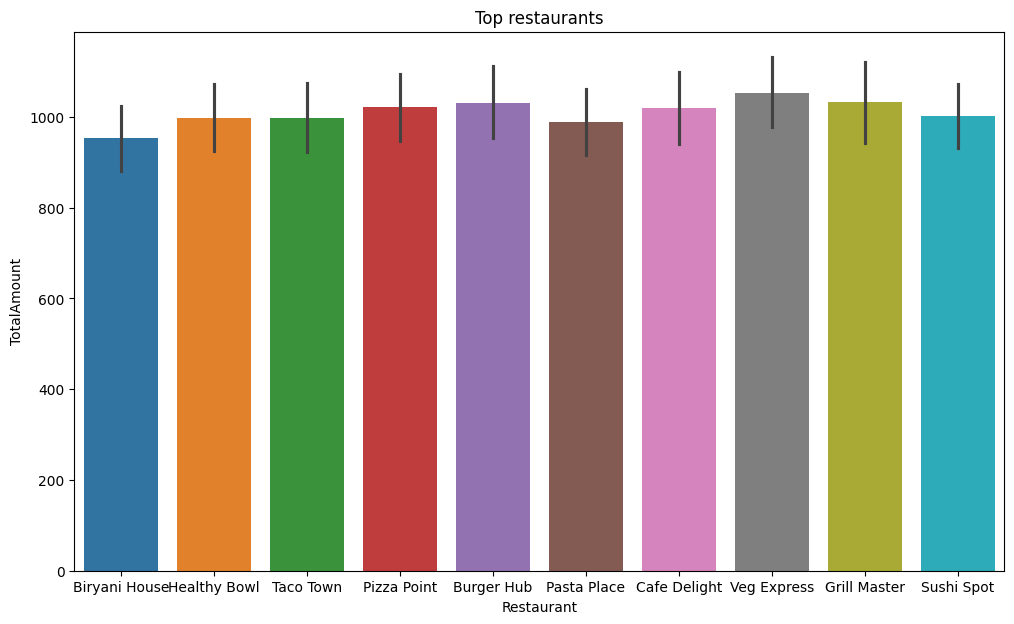

In [83]:
# Top restaurants

plt.figure(figsize=(12,7))
sns.barplot(data=data,x='Restaurant',y='TotalAmount',hue='Restaurant')
plt.title("Top restaurants")
plt.show()

In [84]:
# Top customers

print("Top customers:")
data.groupby('CustomerID')['TotalAmount'].sum().sort_values(ascending=False).head(10)

Top customers:


,TotalAmount
CustomerID,
1141,14134.08
1695,13501.95
1595,12656.74
1092,11249.61
1774,10878.03
1792,10851.75
1117,10767.46
1394,10762.00
1403,10651.21


In [85]:
# Revenue by city

print("Revenue by city:")
data.groupby('City')['TotalAmount'].sum().sort_values(ascending=False)

Revenue by city:


,TotalAmount
City,
Delhi,661013.09
Mumbai,611626.51
Hyderabad,606399.53
Chennai,581559.79
Bangalore,567818.39


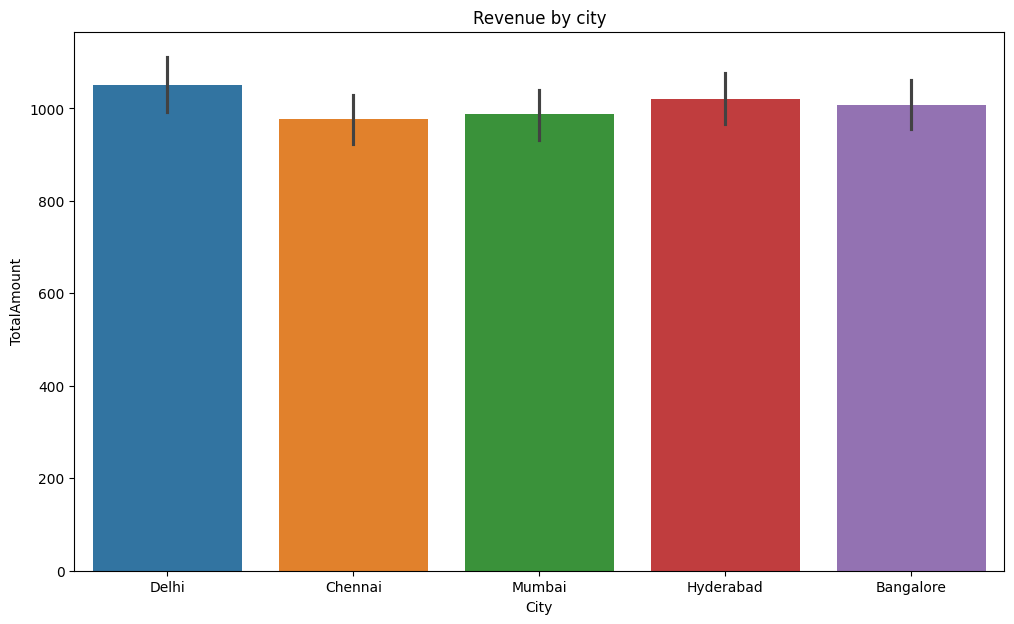

In [86]:

plt.figure(figsize=(12,7))
sns.barplot(data=data,x='City',y='TotalAmount',hue='City')
plt.title("Revenue by city")
plt.show()

In [87]:
# Payment method distribution

print("Payment method distribution:")
payment_met = data['PaymentMethod'].value_counts()
payment_met

Payment method distribution:


,count
PaymentMethod,
UPI,1050
Cash,987
Card,963


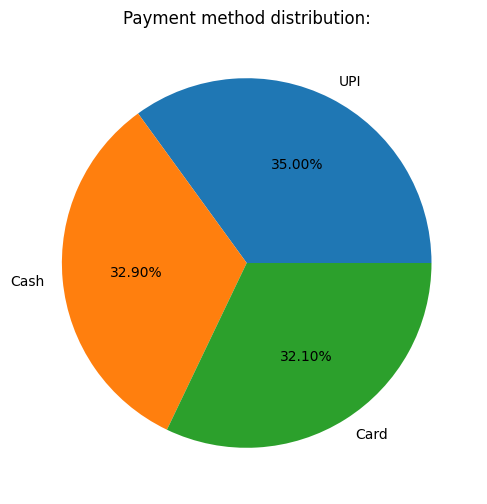

In [88]:
plt.figure(figsize=(6,6))
plt.pie(payment_met,labels=payment_met.index,autopct="%1.2f%%")
plt.title("Payment method distribution:")
plt.show()


In [89]:
# Customer ratings

print("Customer ratings:")
rating = data['CustomerRating'].value_counts(ascending=True)
rating

Customer ratings:


,count
CustomerRating,
5,581
2,592
1,595
3,605
4,627


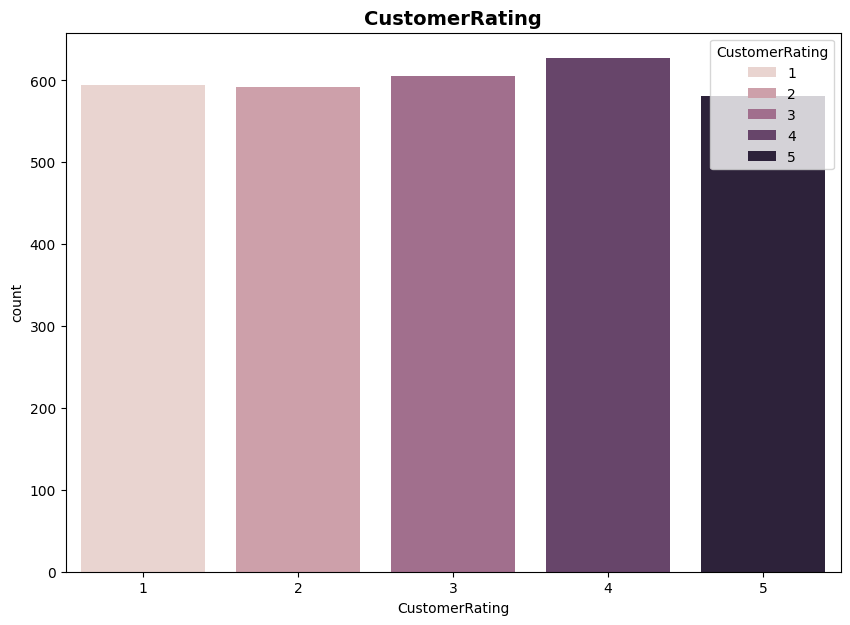

In [90]:
from ipywidgets import Tab
plt.figure(figsize=(10,7))
sns.countplot(data=data,x="CustomerRating",hue="CustomerRating")
plt.title("CustomerRating", fontsize=14, fontweight='bold')
plt.show()

## Task 4 – Association Rule Learning (Apriori)

● Create transaction baskets

● Generate frequent itemsets

● Generate association rules

● Calculate:
* ○ Support
* ○ Confidence
* ○ Lift

● Identify:
* ○ Frequently purchased food combinations

In [91]:
data[['CustomerID','OrderDate','FoodItem']]

,CustomerID,OrderDate,FoodItem
0,1229,2024-05-05,Pizza
1,1224,2024-02-17,Wrap
2,1604,2024-08-17,Salad
3,1105,2024-06-21,Taco
4,1550,2024-08-23,Wrap
...,...,...,...
2995,1024,2024-04-24,Sandwich
2996,1792,2024-10-26,Burger
2997,1738,2024-05-02,Wrap
2998,1505,2024-06-25,Pasta


In [92]:
import warnings
warnings.filterwarnings("ignore")

items = (data['FoodItem'].unique())
items

array(['Pizza', 'Wrap', 'Salad', 'Taco', 'Sandwich', 'Biryani', 'Sushi',
       'Burger', 'Coffee', 'Pasta'], dtype=object)

In [93]:
# Create transaction baskets

basket = data.groupby(['CustomerID', 'OrderDate'])['FoodItem'].apply(list).reset_index()
basket

,CustomerID,OrderDate,FoodItem
0,1001,2024-06-02,[Pasta]
1,1001,2024-07-23,[Coffee]
2,1002,2024-08-11,[Salad]
3,1003,2024-04-10,[Burger]
4,1003,2024-04-21,[Pasta]
...,...,...,...
2981,1799,2024-05-12,[Sushi]
2982,1799,2024-06-20,[Biryani]
2983,1800,2024-07-09,[Wrap]
2984,1800,2024-10-12,[Pizza]


In [94]:
transactions = basket['FoodItem'].tolist()
print(transactions)

[['Pasta'], ['Coffee'], ['Salad'], ['Burger'], ['Pasta'], ['Pizza'], ['Salad'], ['Burger'], ['Biryani'], ['Coffee'], ['Taco'], ['Sandwich'], ['Sandwich'], ['Sandwich'], ['Taco'], ['Biryani'], ['Pasta'], ['Biryani'], ['Salad'], ['Taco'], ['Sandwich'], ['Burger'], ['Sandwich'], ['Pasta'], ['Sushi'], ['Biryani'], ['Wrap'], ['Biryani'], ['Burger'], ['Sandwich'], ['Biryani'], ['Sushi'], ['Wrap'], ['Sushi'], ['Wrap'], ['Wrap'], ['Sandwich'], ['Sushi'], ['Sandwich'], ['Taco'], ['Taco'], ['Burger'], ['Biryani'], ['Salad'], ['Coffee'], ['Wrap'], ['Burger'], ['Taco'], ['Sushi'], ['Wrap'], ['Sushi'], ['Pasta'], ['Burger'], ['Biryani'], ['Wrap'], ['Taco'], ['Sandwich'], ['Sushi'], ['Salad'], ['Wrap'], ['Biryani'], ['Sandwich'], ['Pizza'], ['Salad'], ['Biryani'], ['Taco'], ['Pizza'], ['Coffee'], ['Burger'], ['Salad'], ['Sandwich'], ['Wrap'], ['Pasta'], ['Wrap'], ['Sushi'], ['Pizza'], ['Pasta'], ['Burger'], ['Taco'], ['Sushi'], ['Sandwich'], ['Salad'], ['Coffee'], ['Sushi'], ['Biryani'], ['Sandwich'

In [95]:
from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
data_encoded = pd.DataFrame(te_array, columns=te.columns_)
data_encoded

,Biryani,Burger,Coffee,Pasta,Pizza,Salad,Sandwich,Sushi,Taco,Wrap
0,False,False,False,True,False,False,False,False,False,False
1,False,False,True,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False
3,False,True,False,False,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
2981,False,False,False,False,False,False,False,True,False,False
2982,True,False,False,False,False,False,False,False,False,False
2983,False,False,False,False,False,False,False,False,False,True
2984,False,False,False,False,True,False,False,False,False,False


In [96]:
# Generate frequent itemsets

from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(data_encoded,min_support=0.05,use_colnames=True)

In [97]:
# Frequently purchased food combinations
frequent_itemsets

,support,itemsets
0,0.111186,(Biryani)
1,0.098125,(Burger)
2,0.104488,(Coffee)
3,0.089752,(Pasta)
4,0.099129,(Pizza)
5,0.099129,(Salad)
6,0.101808,(Sandwich)
7,0.099799,(Sushi)
8,0.090087,(Taco)
9,0.111186,(Wrap)


In [102]:
# Generate association rules

rules = association_rules(frequent_itemsets,metric='confidence',min_threshold=0.6)
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


In [103]:
# Support,Confidence,Lift

High_confi=rules[['antecedents','consequents','support',	'confidence',	'lift']].sort_values(by='confidence',ascending=False)
High_confi

,antecedents,consequents,support,confidence,lift


##Task 5 – Recommendation System

~ **Build a recommendation function using Apriori results.**

In [109]:
data.head(3)

,OrderID,CustomerID,Restaurant,FoodItem,Quantity,OrderValue,TotalAmount,DeliveryTime_Minutes,CustomerRating,City,PaymentMethod,OrderDate,Year,Month,Weekday
0,1,1229,Biryani House,Pizza,1,465.61,465.61,57,1,Delhi,UPI,2024-05-05,2024,5,Sunday
1,2,1224,Healthy Bowl,Wrap,4,96.53,386.12,42,5,Chennai,Cash,2024-02-17,2024,2,Saturday
2,3,1604,Taco Town,Salad,5,298.15,1490.75,10,2,Mumbai,Card,2024-08-17,2024,8,Saturday


In [110]:
rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


In [112]:
def recommend(food_item):

    recommendations = []

    for index, row in rules.iterrows():

        if food_item in row['antecedents']:

            recommendations.extend(list(row['consequents']))

    return list(set(recommendations))

In [117]:
recommend("Burger")

[]

In [119]:
# Recommended food_item

food_item = "Burger"

result = recommend(food_item)

print("Food Item:", food_item)
print("Recommended Items:", result)

Food Item: Burger
Recommended Items: []


##Task 6 – Time Series Forecasting

● Aggregate monthly orders/sales

● Analyze trends and seasonality

● Build an ARIMA model

● Forecast

In [120]:
import matplotlib.pyplot as plt
import numpy as np

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

In [121]:
# Aggregate monthly orders/sales

monthly_data = data.set_index('OrderDate').resample('MS').agg({

    'OrderID': 'nunique',
    'TotalAmount': 'sum'

})

monthly_data.columns = ['Total_Orders', 'Total_Sales']

monthly_data

,Total_Orders,Total_Sales
OrderDate,,
2024-01-01,240,228733.65
2024-02-01,255,279640.20
2024-03-01,250,239471.27
2024-04-01,257,271320.02
2024-05-01,271,274833.23
2024-06-01,217,216166.10
2024-07-01,276,275629.83
2024-08-01,266,265599.52
2024-09-01,224,216775.56


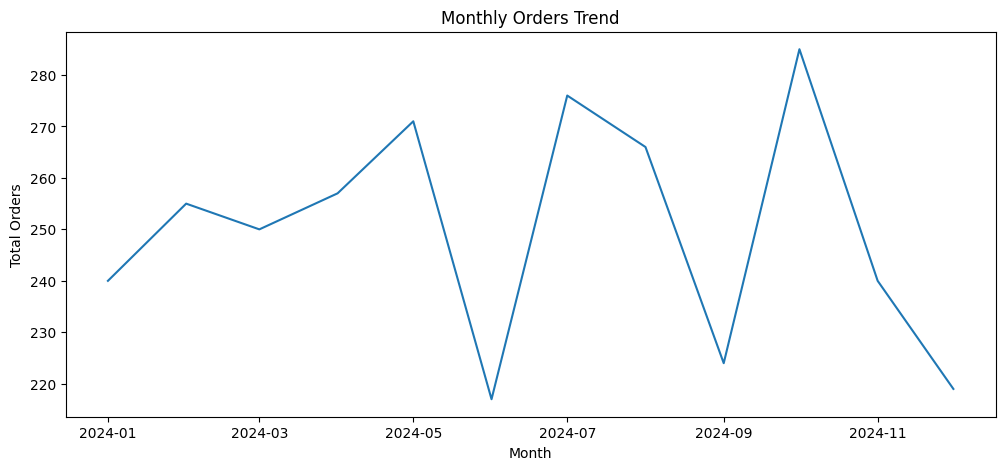

In [122]:
# Analyze trends and seasonality

plt.figure(figsize=(12,5))

plt.plot(monthly_data['Total_Orders'])

plt.title("Monthly Orders Trend")
plt.xlabel("Month")
plt.ylabel("Total Orders")

plt.show()

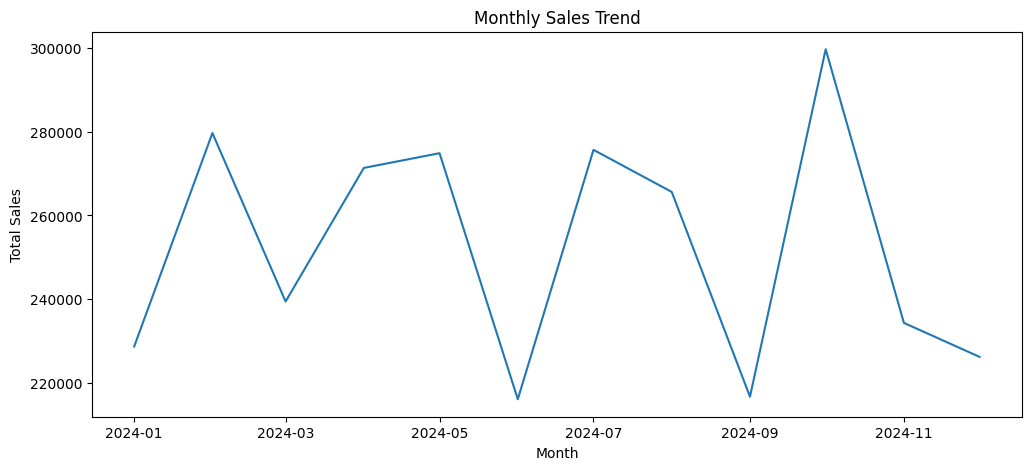

In [123]:
plt.figure(figsize=(12,5))

plt.plot(monthly_data['Total_Sales'])

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.show()

In [124]:
adf_result = adfuller(monthly_data['Total_Sales'])

print("ADF Statistics:", adf_result[0])
print("P Value:", adf_result[1])

ADF Statistics: -4.3192107691157915
P Value: 0.0004113889623327058


In [125]:
monthly_diff = monthly_data['Total_Sales'].diff(1)

monthly_diff

,Total_Sales
OrderDate,
2024-01-01,NaN
2024-02-01,50906.55
2024-03-01,-40168.93
2024-04-01,31848.75
2024-05-01,3513.21
2024-06-01,-58667.13
2024-07-01,59463.73
2024-08-01,-10030.31
2024-09-01,-48823.96


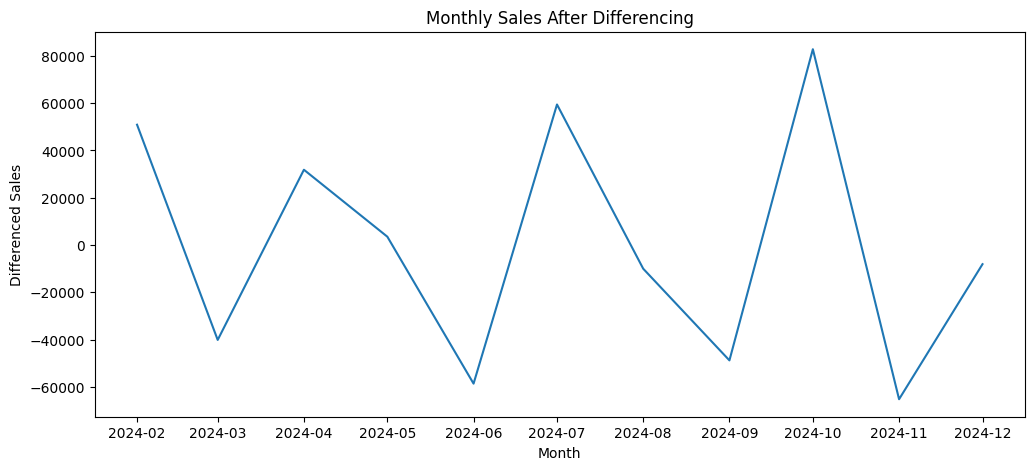

In [126]:
plt.figure(figsize=(12,5))

plt.plot(monthly_diff)

plt.title("Monthly Sales After Differencing")
plt.xlabel("Month")
plt.ylabel("Differenced Sales")

plt.show()

In [127]:
# Build an ARIMA model

arima_model = ARIMA(
    monthly_data['Total_Sales'],
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:            Total_Sales   No. Observations:                   12
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -134.455
Date:                Wed, 11 Nov 2026   AIC                            274.910
Time:                        15:46:23   BIC                            276.104
Sample:                    01-01-2024   HQIC                           274.158
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2908      1.892      0.154      0.878      -3.418       4.000
ma.L1         -0.3743      1.901     -0.197      0.844      -4.101       3.352
sigma2      1.718e+09   1.71e-10      1e+19      0.0

In [128]:
# Forecast

forecast = arima_result.forecast(steps=3)

forecast

,predicted_mean
2025-01-01,228209.199924
2025-02-01,228777.036883
2025-03-01,228942.171640


In [131]:
# Display future forecast

future_dates = pd.date_range(
    start=monthly_data.index[-1] + pd.offsets.MonthBegin(1),
    periods=3,
    freq='MS'
)

forecast_df = pd.DataFrame({

    'Month': future_dates,
    'Forecasted_Sales': forecast.values

})

forecast_df

,Month,Forecasted_Sales
0,2025-01-01,228209.199924
1,2025-02-01,228777.036883
2,2025-03-01,228942.171640


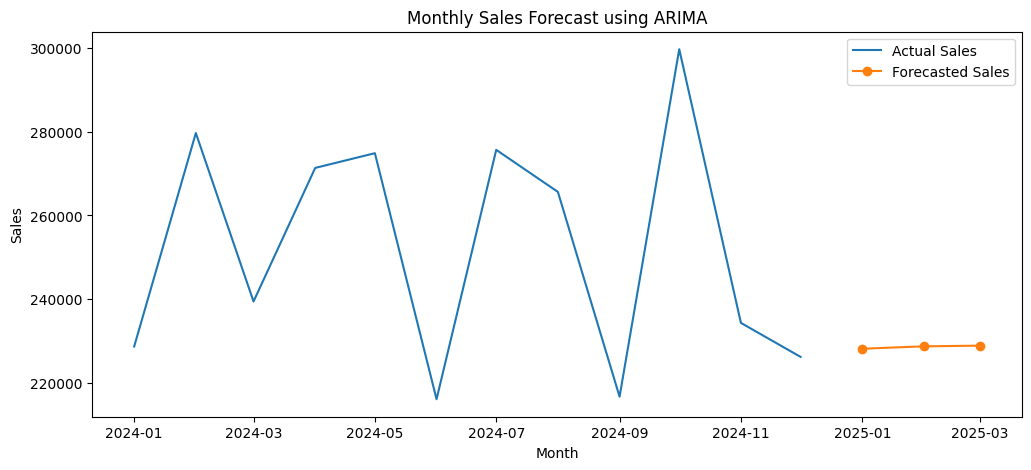

In [130]:
# Visualise actual sales and forecast

plt.figure(figsize=(12,5))

plt.plot(
    monthly_data.index,
    monthly_data['Total_Sales'],
    label='Actual Sales'
)

plt.plot(
    future_dates,
    forecast.values,
    marker='o',
    label='Forecasted Sales'
)

plt.title("Monthly Sales Forecast using ARIMA")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.legend()
plt.show()